# 03. Preprocessing and features (Task Complexity)

**Goal.** Decide how the raw Task Complexity columns become model inputs and how the training labels are built, using **validation results only**.
The outer test groups are not touched.

Decisions tested on the same 20 combinations as notebook 02:

1. **Which features, in which form?** The proposal's features and simpler or richer subsets (see the variants table).
2. **Which training labels?** Rated records only, plus labels for unrated records from a small model fitted on the rated ones, with or
   without synthetic records; and the weight of those propagated labels (1 or 0.3).
3. **How to treat students with no activity?** Not applicable here (a student can have assigned tasks without commits).

**Leak-proof by construction.** The imputer, the scaler and the label model are fitted on the training rows of each combination only
(`../ml_lib/features.py`). Missing values are imputed with the training median and flagged.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "1"  # tiny data: one thread is faster than OpenMP overhead
sys.path.insert(0, str(Path("../ml_lib").resolve()))
warnings.filterwarnings("ignore")

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from core import (GROUPS, SEED, Factor, environment, group_bootstrap, load, log_run, log_signed, make_splits, metrics,
                  paired_diff_bootstrap)
from features import (LABEL_SOURCES, Propagator, design, fit_linear, fit_model, fit_ridge_loo, linear_model, make_model, training_set,
                      transform)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.width", 180)
pd.set_option("display.max_columns", 40)

F = Factor(key="task_complexity", title="Task Complexity", folder=Path(".").resolve(), dataset_file="task_complexity_dataset.csv", label="rater_task_complexity", activity="E_CC")
LABEL, ACT = F.label, F.activity
PROPOSAL = [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log')]
VARIANTS = {'proposal 5 (log counts)': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log')], 'proposal 5 (raw)': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'raw'), ('TC_DR', 'raw'), ('TC_CB', 'raw')], '4 features (no DR)': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_CB', 'log')], 'SP, SC, FI': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log')], 'board only (SP, SC)': [('TC_SP', 'raw'), ('TC_SC', 'raw')], 'code only (FI, DR, CB)': [('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log')], 'SP only': [('TC_SP', 'raw')], 'proposal 5 + total points': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log'), ('TC_SP_total', 'log')], 'proposal 5 + tasks assigned': [('TC_SP', 'raw'), ('TC_SC', 'raw'), ('TC_FI', 'log'), ('TC_DR', 'log'), ('TC_CB', 'log'), ('RF_tasks_assigned', 'raw')]}
FEATURES = ['TC_SP', 'TC_SC', 'TC_FI', 'TC_DR', 'TC_CB']
ZERO_RULE_OK = False
d = load(F)
real = d[d.source == "real"]
syn = d[d.source == "synthetic"]
gold = real[real.label_source == "rater"]
active = real[real[ACT] > 0]
print(F.title, d.shape)

Task Complexity (744, 26)


In [2]:
splits = pd.read_csv(F.splits)
combos = [(t, v, g[["record_id", "role"]]) for (t, v), g in splits.groupby(["outer_test", "inner_val"])]
GOLD = d[d.label_source == "rater"]
print(len(combos), "combinations;", len(GOLD), "rated records;", len(VARIANTS), "feature variants")
pd.DataFrame({"inputs": {n: ", ".join(f"{c}{'' if tf == 'raw' else ' (' + tf + ')'}" for c, tf in spec) for n, spec in VARIANTS.items()}})

20 combinations; 20 rated records; 9 feature variants


,inputs
proposal 5 (log counts),"TC_SP, TC_SC, TC_FI (log), TC_DR (log), TC_CB ..."
proposal 5 (raw),"TC_SP, TC_SC, TC_FI, TC_DR, TC_CB"
4 features (no DR),"TC_SP, TC_SC, TC_FI (log), TC_CB (log)"
"SP, SC, FI","TC_SP, TC_SC, TC_FI (log)"
"board only (SP, SC)","TC_SP, TC_SC"
"code only (FI, DR, CB)","TC_FI (log), TC_DR (log), TC_CB (log)"
SP only,TC_SP
proposal 5 + total points,"TC_SP, TC_SC, TC_FI (log), TC_DR (log), TC_CB ..."
proposal 5 + tasks assigned,"TC_SP, TC_SC, TC_FI (log), TC_DR (log), TC_CB ..."


## 1. Proof that nothing leaks

For one combination, the imputer and scaler inside the model learn only from the training rows. We change every validation and test feature
drastically and check the training data and its labels do not move.

In [3]:
test, val, roles = combos[0]
spec = VARIANTS[list(VARIANTS)[0]]
featurize = lambda f: design(f, spec)  # noqa: E731
X, y, w, ids = training_set(d, roles, featurize, LABEL, PROPOSAL, "rated + propagated (real)")
held = roles[roles.role.isin(["val", "test"])].record_id
d2 = d.copy()
for col in {c for c, _ in spec} | {c for c, _ in PROPOSAL}:
    d2.loc[held, col] = 9999
X2, y2, w2, ids2 = training_set(d2, roles, lambda f: design(f, spec), LABEL, PROPOSAL, "rated + propagated (real)")
assert np.array_equal(X, X2, equal_nan=True) and np.allclose(y, y2), "training data changed when validation or test rows changed"
m = fit_linear(linear_model(1.0), X, y, w)
assert np.allclose(m.named_steps["standardscaler"].mean_, np.nanmean(m.named_steps["simpleimputer"].transform(X), axis=0)), "scaler not fitted on training rows"
print("OK: training data, propagated labels and scaler depend only on the training rows")
print("training rows in this combination:", len(ids), "| rated:", int((w == 1).sum()))

OK: training data, propagated labels and scaler depend only on the training rows
training rows in this combination: 45 | rated: 45


## 2. Label construction

For unrated rows the label comes from a Ridge model fitted on the rated rows of the training groups. How good is it on held-out rated rows?
That is the quality ceiling of every propagated label.

In [4]:
rows = []
for test, val, roles in combos:
    t = d.loc[roles[roles.role == "train"].record_id]
    prop = Propagator(t[(t.source == "real") & (t.label_source == "rater")], PROPOSAL, LABEL)
    v = d.loc[[i for i in roles[roles.role == "val"].record_id if i in GOLD.index]]
    rows += [(test, val, y, p) for y, p in zip(v[LABEL], prop.predict(v))]
lab = pd.DataFrame(rows, columns=["outer_test", "inner_val", "y", "pred"])
m = metrics(lab.y, lab.pred)
print(f"label model on held-out rated records: MAE {m['MAE']:.3f}, RMSE {m['RMSE']:.3f}, Pearson {m['pearson']:.3f}, n={m['n']}")

label model on held-out rated records: MAE 0.111, RMSE 0.145, Pearson 0.233, n=80


## 3. The experiment

For each variant, label source, weight and `alpha` in {0.1, 1, 10} (varied only to check the conclusion does not depend on it; it is tuned
in notebook 04): train Ridge on each combination's training rows, predict the rated records of the validation group, pool over the 20
combinations.

In [5]:
WEIGHTS, ALPHA_GRID = [1.0, 0.3], [0.1, 1.0, 10.0]
RULES = [False, True] if ZERO_RULE_OK else [False]
records = []
for variant, spec in VARIANTS.items():
    featurize = lambda f, spec=spec: design(f, spec)  # noqa: E731
    for source in LABEL_SOURCES:
        for weight in (WEIGHTS if source != "rated only" else [1.0]):
            for rule in RULES:
                for test, val, roles in combos:
                    X, y, w, ids = training_set(d, roles, featurize, LABEL, PROPOSAL, source, weight)
                    if rule:
                        keep = d.loc[ids, ACT].to_numpy() > 0
                        X, y, w = X[keep], y[keep], w[keep]
                    v = d.loc[[i for i in roles[roles.role == "val"].record_id if i in GOLD.index]]
                    Xv = featurize(v)
                    for alpha in ALPHA_GRID:
                        p = np.clip(fit_linear(linear_model(alpha), X, y, w).predict(Xv), 0, 1)
                        if rule:
                            p = np.where(v[ACT].to_numpy() == 0, 0.0, p)
                        records += [(variant, source, weight, rule, alpha, test, val, r, g, yy, pp, a)
                                    for r, g, yy, pp, a in zip(v.record_id, v.group, v[LABEL], p, v[ACT])]
res = pd.DataFrame(records, columns=["variant", "label_source", "weight", "zero_rule", "alpha", "outer_test", "inner_val", "record_id", "group", "y", "pred", "activity"])
res["abs_err"] = (res.pred - res.y).abs()
res.to_csv(F.results / "preprocessing_validation_predictions.csv", index=False)
print(len(res), "predictions;", res.groupby(["variant", "label_source", "weight", "zero_rule"]).ngroups, "configurations")

10800 predictions; 45 configurations


## 4. Results

In [6]:
cfg = ["variant", "label_source", "weight", "zero_rule"]
table = res.groupby(cfg + ["alpha"]).abs_err.mean().groupby(cfg).mean().rename("MAE (mean over alpha)").reset_index()
act = res[res.activity > 0].groupby(cfg).abs_err.mean().rename("MAE active only").reset_index()
table = table.merge(act, on=cfg).sort_values("MAE (mean over alpha)").reset_index(drop=True)
table.round(3).head(15)

,variant,label_source,weight,zero_rule,MAE (mean over alpha),MAE active only
0,proposal 5 + total points,rated + propagated (real),0.3,False,0.103,0.105
1,proposal 5 + tasks assigned,rated only,1.0,False,0.103,0.108
2,proposal 5 + tasks assigned,rated + propagated (real),0.3,False,0.105,0.108
3,proposal 5 + total points,rated only,1.0,False,0.105,0.108
4,proposal 5 + total points,rated + propagated (real),1.0,False,0.107,0.110
5,proposal 5 + total points,rated + propagated (real + synthetic),0.3,False,0.108,0.110
6,proposal 5 (log counts),rated + propagated (real),0.3,False,0.108,0.111
7,proposal 5 + tasks assigned,rated + propagated (real),1.0,False,0.109,0.111
8,proposal 5 + tasks assigned,rated + propagated (real + synthetic),0.3,False,0.109,0.112
9,proposal 5 + total points,rated + propagated (real + synthetic),1.0,False,0.110,0.112


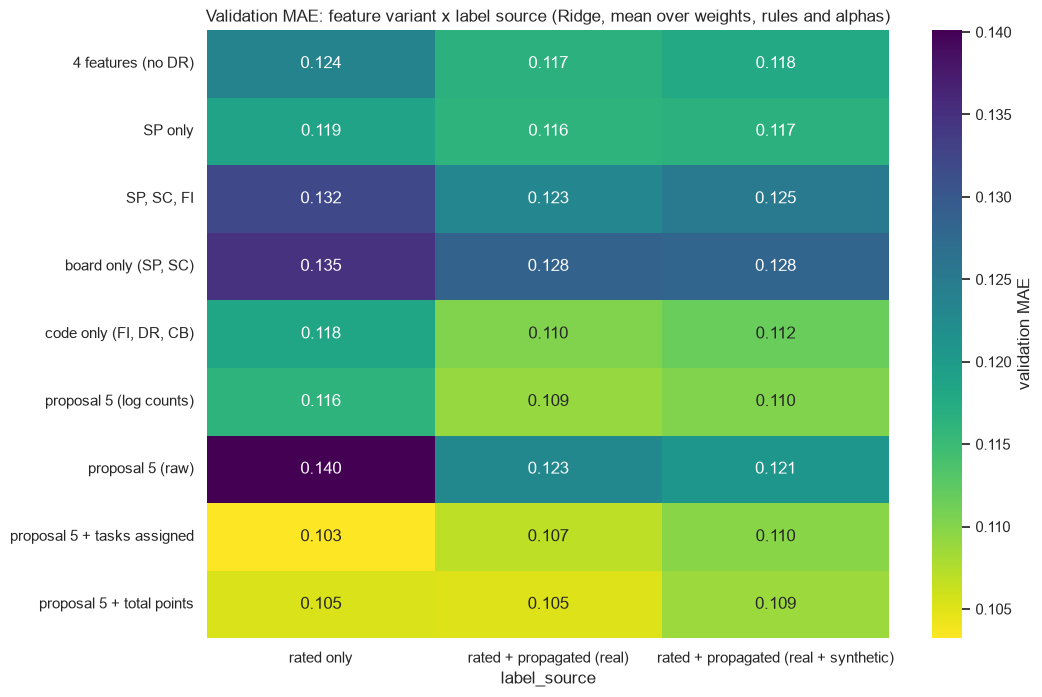

weight,0.3,1.0
variant,,
4 features (no DR),0.117,0.120
SP only,0.117,0.117
"SP, SC, FI",0.124,0.127
"board only (SP, SC)",0.129,0.130
"code only (FI, DR, CB)",0.111,0.113
proposal 5 (log counts),0.109,0.112
proposal 5 (raw),0.121,0.128
proposal 5 + tasks assigned,0.107,0.107
proposal 5 + total points,0.105,0.107


In [7]:
pivot = res.groupby(["variant", "label_source"]).abs_err.mean().unstack("label_source")[LABEL_SOURCES]
fig, ax = plt.subplots(figsize=(11, 0.6 * len(VARIANTS) + 2.5))
sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis_r", ax=ax, cbar_kws={"label": "validation MAE"})
ax.set(title="Validation MAE: feature variant x label source (Ridge, mean over weights, rules and alphas)", ylabel="")
plt.show()
rule_effect = res.groupby(["variant", "zero_rule"]).abs_err.mean().unstack("zero_rule") if ZERO_RULE_OK else None
rule_effect.round(3) if ZERO_RULE_OK else res.groupby(["variant", "weight"]).abs_err.mean().unstack("weight").round(3)

## 5. Choosing, by a rule written before looking

In [8]:
def simplicity(row):
    return (len(VARIANTS[row.variant]), LABEL_SOURCES.index(row.label_source), row.weight != 1.0, bool(row.zero_rule))

best = table.iloc[0]
sel = res[(res.variant == best.variant) & (res.label_source == best.label_source) & (res.weight == best.weight) & (res.zero_rule == best.zero_rule)]
rng = np.random.default_rng(SEED)
groups = sel.group.unique()
boot = [np.mean(np.concatenate([sel[sel.group == g].abs_err.to_numpy() for g in rng.choice(groups, len(groups), replace=True)])) for _ in range(1000)]
se = float(np.std(boot))
near = table[table["MAE (mean over alpha)"] <= best["MAE (mean over alpha)"] + se].copy()
near["rank"] = near.apply(simplicity, axis=1)
choice = near.sort_values("rank").iloc[0]
print(f"best: {best.variant} | {best.label_source} | weight {best.weight} | zero rule {best.zero_rule} | MAE {best['MAE (mean over alpha)']:.3f} (SE {se:.3f})")
print(f"settings within one SE: {len(near)}")
print(f"chosen (simplest within one SE): {choice.variant} | {choice.label_source} | weight {choice.weight} | zero rule {choice.zero_rule} | MAE {choice['MAE (mean over alpha)']:.3f}")
near.drop(columns="rank").round(3).head(12)

best: proposal 5 + total points | rated + propagated (real) | weight 0.3 | zero rule False | MAE 0.103 (SE 0.028)
settings within one SE: 42
chosen (simplest within one SE): SP only | rated only | weight 1.0 | zero rule False | MAE 0.119


,variant,label_source,weight,zero_rule,MAE (mean over alpha),MAE active only
0,proposal 5 + total points,rated + propagated (real),0.3,False,0.103,0.105
1,proposal 5 + tasks assigned,rated only,1.0,False,0.103,0.108
2,proposal 5 + tasks assigned,rated + propagated (real),0.3,False,0.105,0.108
3,proposal 5 + total points,rated only,1.0,False,0.105,0.108
4,proposal 5 + total points,rated + propagated (real),1.0,False,0.107,0.110
5,proposal 5 + total points,rated + propagated (real + synthetic),0.3,False,0.108,0.110
6,proposal 5 (log counts),rated + propagated (real),0.3,False,0.108,0.111
7,proposal 5 + tasks assigned,rated + propagated (real),1.0,False,0.109,0.111
8,proposal 5 + tasks assigned,rated + propagated (real + synthetic),0.3,False,0.109,0.112
9,proposal 5 + total points,rated + propagated (real + synthetic),1.0,False,0.110,0.112


In [9]:
decision = {"variant": choice.variant, "label_source": choice.label_source, "pseudo_weight": float(choice.weight), "zero_rule": bool(choice.zero_rule),
            "features": [c for c, _ in VARIANTS[choice.variant]], "validation_MAE": round(float(choice["MAE (mean over alpha)"]), 4),
            "standard_error": round(se, 4), "rule": "lowest validation MAE, then simplest within one bootstrap SE"}
(F.results / "preprocessing_choice.json").write_text(json.dumps(decision, indent=2))
log_run(F, "03_preprocessing_and_features", choice.variant, f"chosen; {choice.label_source}; weight {choice.weight}; zero rule {choice.zero_rule}; validation",
        {"MAE": decision["validation_MAE"], "SE": decision["standard_error"]})
print(json.dumps(decision, indent=2))

{
  "variant": "SP only",
  "label_source": "rated only",
  "pseudo_weight": 1.0,
  "zero_rule": false,
  "features": [
    "TC_SP"
  ],
  "validation_MAE": 0.1187,
  "standard_error": 0.0278,
  "rule": "lowest validation MAE, then simplest within one bootstrap SE"
}


## 6. Reading the results

Validation MAE, pooled over the 20 combinations, Ridge; the always-predict-the-mean baseline is 0.128 (notebook 02):

| Question | Answer from the tables above |
|---|---|
| Best variant | The proposal's five features plus the sprint's total story points, with propagated labels: **0.103**. The standard error is **0.028**. |
| Is the log transform needed? | Yes. Raw counts 0.121-0.128, the same features in log 0.109-0.112 (`FI`, `DR` and `CB` are very skewed). |
| Do the code features (`FI`, `DR`, `CB`) help over the board features (`SP`, `SC`)? | **Yes.** Code only 0.111-0.113; board only 0.129-0.130 (no better than the mean). |
| Does dependency reach (`DR`) help? | Barely. Without it 0.117-0.120 vs 0.109-0.112 with it. |
| Do propagated labels help? | A little for the five-feature models (0.103-0.108 with them vs 0.105-0.107 without), nothing decisive. |
| Does the weight on propagated labels matter? | No (0.3 vs 1.0 differ by 0.001-0.006). |

**What the rule chose.** Every variant of five or more features lies within about one standard error (0.028) of the best, because the data
cannot tell them apart; the rule's simplest option, **story points only** (rated labels, MAE 0.119), is saved to
`training/results/preprocessing_choice.json`. That is barely better than always predicting the mean (0.128).

**What it means.**
- No feature set gets Task Complexity below about 0.10, and differences between sets (0.103-0.130) are smaller than the noise (0.028).
- The only reliable findings are that the code-derived features carry more than the board features, and that log transforms are needed.
- With a label range of only 0.05-0.65 (sd 0.145) and 9-15 rated records per fold, this factor cannot be learned reliably from this
  dataset. Notebook 04 tests whether non-linear models do better; the 'chosen' story-points model is included there next to the proposal's
  five features and the board features.

Next: **04. Hyperparameter tuning**.